## Optimización y Aprendizaje Automático II

### NumPy para la materia: arrays, álgebra lineal y cálculo vectorizado

Código del apunte de repaso *NumPy para la materia: arrays, álgebra lineal y cálculo vectorizado*. Las explicaciones están en el PDF: ejecutá cada celda mientras lo leés, y modificá los ejemplos para ver qué pasa.

**Cómo leerlo.**

---
#### 1. Crear arrays y mirar su forma

In [1]:
import numpy as np
np.set_printoptions(precision=3, suppress=True)  # salida más legible

a = np.array([1.0, 2.0, 3.0])  # vector
A = np.array([[1, 2, 3], [4, 5, 6]])  # matriz 2x3
print(a.shape, a.ndim, a.dtype)
print(A.shape, A.ndim, A.dtype)

(3,) 1 float64
(2, 3) 2 int64


In [2]:
print(np.zeros((2, 3)))  # matriz de ceros 2x3 (¡la forma va entre paréntesis!)
print(np.ones(4))  # vector de unos
print(np.full(3, 7.0))  # vector con todos los elementos iguales a 7
print(np.eye(3))  # identidad 3x3
print(np.diag([1.0, 2.0]))  # matriz diagonal con esos elementos
print(np.arange(0, 10, 2))  # 0, 2, 4, 6, 8 (no incluye el 10)
print(np.linspace(0, 1, 5))  # 5 puntos equiespaciados entre 0 y 1 (incluye ambos)

[[0. 0. 0.]
 [0. 0. 0.]]
[1. 1. 1. 1.]
[7. 7. 7.]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[[1. 0.]
 [0. 2.]]
[0 2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]


**Tipos de datos.**

In [3]:
v = np.array([1, 2, 3])
v[0] = 0.7
print(v)  # el 0.7 se perdió

v = np.array([1, 2, 3], dtype=float)  # o bien v.astype(float)
v[0] = 0.7
print(v)

[0 2 3]
[0.7 2.  3. ]


**Números aleatorios.**

In [4]:
rng = np.random.default_rng(0)

X = rng.normal(size=(5, 3))  # 5 muestras, 3 variables, N(0, 1)
eps = rng.normal(0, 0.5, size=5)  # vector N(0, 0.5^2)
u = rng.uniform(-10, 10, size=5)  # vector Unif(-10, 10)
indices = rng.choice(5, size=2, replace=False)  # 2 índices distintos al azar
print(X.shape, eps.shape, u.shape, indices)

(5, 3) (5,) (5,) [1 3]


---
#### 2. Vectores: `(n,)` no es lo mismo que `(n, 1)`

In [5]:
v = np.array([1., 2., 3.])
print(v.shape, v.T.shape)  # .T no cambia nada en 1D

col = v[:, None]  # (3, 1), equivalente: v.reshape(-1, 1)
fila = v[None, :]  # (1, 3), equivalente: v.reshape(1, -1)
print(col.shape, fila.shape)
print(col.ravel().shape)  # volver a 1D: .ravel() o col[:, 0]

(3,) (3,)
(3, 1) (1, 3)
(3,)


In [6]:
y = np.array([1., 2., 3.])  # (3,)
y_hat = np.array([[1.], [2.], [4.]])  # (3, 1)

r = y - y_hat
print(r.shape)  # (3, 3) !!
print("error cuadrático medio incorrecto:", np.mean(r**2))
print("error cuadrático medio correcto:", np.mean((y - y_hat.ravel())**2))

(3, 3)
error cuadrático medio incorrecto: 2.3333333333333335
error cuadrático medio correcto: 0.3333333333333333


---
#### 3. Indexación y selección

In [7]:
X = np.arange(12, dtype=float).reshape(4, 3)  # 4 muestras, 3 variables
print(X)
print(X[0].shape)  # fila 0 (muestra 0) -> (3,)
print(X[:, 1].shape)  # columna 1 (variable 1) -> (4,)
print(X[:, [1]].shape)  # columna 1 como matriz -> (4, 1)
print(X[1:3, :2])  # filas 1 y 2, columnas 0 y 1 (el final no se incluye)
print(X[-1])  # última fila

[[ 0.  1.  2.]
 [ 3.  4.  5.]
 [ 6.  7.  8.]
 [ 9. 10. 11.]]
(3,)
(4,)
(4, 1)
[[3. 4.]
 [6. 7.]]
[ 9. 10. 11.]


**Máscaras booleanas.**

In [8]:
y = np.array([0, 1, 0, 1])

print(y == 1)  # máscara
print(X[y == 1])  # filas donde y vale 1
print(np.sum(y == 1))  # cuántos elementos cumplen la condición
print(np.mean(X[:, 0] > 4))  # proporción de filas con X[i, 0] > 4

[False  True False  True]
[[ 3.  4.  5.]
 [ 9. 10. 11.]]
2
0.5


**Posiciones: `np.where`, `argmax` y `argsort`.**

In [9]:
z = np.array([-2., 0.5, 3., -0.1])
print(np.where(z >= 0, 1, 0))  # 1 si z >= 0, 0 si no
print(np.where(z >= 0)[0])  # posiciones de los z >= 0
print(np.argmax(z), np.argmin(z))  # posición del máximo y del mínimo
print(np.argsort(z))  # posiciones de menor a mayor
print(z[np.argsort(z)[:2]])  # los dos valores más chicos

[0 1 1 0]
[1 2]
2 0
[0 3 1 2]
[-2.  -0.1]


In [10]:
X = np.zeros((3, 2))
B = X[:2]
B[0, 0] = 99
print(X[0, 0])  # X también cambió

C = X[:2].copy()
C[0, 0] = -1
print(X[0, 0])  # sigue en 99.0

99.0
99.0


---
#### 4. Elemento a elemento vs. álgebra matricial

In [11]:
A = np.array([[1., 2.], [3., 4.]])
B = np.array([[0., 1.], [1., 0.]])
print(A * B)  # elemento a elemento
print(A @ B)  # producto matricial

X = rng.normal(size=(6, 3))
theta = np.array([1., -2., 0.5])
print((X @ theta).shape)  # matriz (6, 3) por vector (3,) -> vector (6,)
print((X.T @ X).shape)  # (3, 3)

[[0. 2.]
 [3. 0.]]
[[2. 1.]
 [4. 3.]]
(6,)
(3, 3)


**El producto interno, de cuatro maneras.**

In [12]:
x = np.array([1., 2., 3.])
y = np.array([4., -1., 0.5])

s = 0.0  # bucle: traducción literal de la sumatoria
for j in range(len(x)):
    s += x[j] * y[j]

print(s, np.sum(x * y), np.dot(x, y), x @ y)

3.5 3.5 3.5 3.5


**Vectores 1D a izquierda y a derecha.**

In [13]:
r = rng.normal(size=6)
print(np.allclose(X @ theta, theta @ X.T), np.allclose(X.T @ r, r @ X))

theta_col = theta[:, None]  # (3, 1)
print((X @ theta_col).shape)  # (6, 1), no (6,)
print((theta_col.T @ X.T).shape)  # (1, 6), no (6,)

True True
(6, 1)
(1, 6)


---
#### 5. Resolver sistemas lineales

In [14]:
A = np.array([
    [3., 1.],
    [1., 2.],
])
b = np.array([9., 8.])

print(np.linalg.solve(A, b))
print(np.linalg.inv(A) @ b)
print(np.linalg.pinv(A) @ b)

[2. 3.]
[2. 3.]
[2. 3.]


**Por qué `solve` y no `inv`.**

In [15]:
i = np.arange(10)
A = 1 / (i[:, None] + i[None, :] + 1)  # matriz de Hilbert (10, 10), por broadcasting (sección 7)
b = A @ np.ones(10)  # la solución exacta es un vector de unos

x_solve = np.linalg.solve(A, b)
x_inv = np.linalg.inv(A) @ b
print(f"residuo con solve: {np.linalg.norm(A @ x_solve - b):.1e}")
print(f"residuo con inv: {np.linalg.norm(A @ x_inv - b):.1e}")

residuo con solve: 5.7e-16
residuo con inv: 4.8e-05


In [16]:
X = rng.normal(size=(100, 3))  # 100 ecuaciones, 3 incógnitas
y = X @ np.array([1., -2., 0.5]) + 0.1 * rng.normal(size=100)

try:
    np.linalg.solve(X, y)
except np.linalg.LinAlgError as e:
    print("solve:", e)

print("pinv:", np.linalg.pinv(X) @ y)
print("lstsq:", np.linalg.lstsq(X, y, rcond=None)[0])

solve: Last 2 dimensions of the array must be square
pinv: [ 1.001 -1.996  0.516]
lstsq: [ 1.001 -1.996  0.516]


In [17]:
S = np.array([
    [1., 2.],
    [2., 4.],
])  # singular: fila 2 = 2 * fila 1
print(np.linalg.det(S), np.linalg.matrix_rank(S))
try:
    np.linalg.inv(S)
except np.linalg.LinAlgError as e:
    print("inv:", e)
print("pinv:", np.linalg.pinv(S) @ np.array([1., 2.]))  # solución de menor norma

0.0 1
inv: Singular matrix
pinv: [0.2 0.4]


---
#### 6. El parámetro `axis`

In [18]:
X = np.array([
    [3., 1., 2.],
    [0., 5., 4.],
])  # (2, 3): 2 muestras, 3 variables

print(X.mean())  # media de todo -> escalar
print(X.mean(axis=0))  # media de cada columna (variable) -> (3,)
print(X.mean(axis=1))  # media de cada fila (muestra) -> (2,)
print(X.argmax(axis=0))  # en cada columna, la fila del máximo -> (3,)
print(X.argmax(axis=1))  # en cada fila, la columna del máximo -> (2,)
print(X.argmin(axis=1))  # en cada fila, la columna del mínimo -> (2,)
print(X.sum(axis=1, keepdims=True).shape)  # conserva la dimensión -> (2, 1)

2.5
[1.5 3.  3. ]
[2. 3.]
[0 1 1]
[0 1]
[1 0]
(2, 1)


In [19]:
P = np.array([
    [0.7, 0.2, 0.1],
    [0.1, 0.3, 0.6],
    [0.2, 0.5, 0.3],
    [0.6, 0.3, 0.1],
])  # (n, K) = (4, 3)

clase = P.argmax(axis=1)  # clase más probable de cada muestra -> (4,)
print(clase)
print(P.max(axis=1))  # su probabilidad -> (4,)
print(P.mean(axis=0))  # probabilidad media de cada clase -> (3,)
print(np.mean(clase == 0))  # proporción de muestras asignadas a la clase 0

[0 2 1 0]
[0.7 0.6 0.5 0.6]
[0.4   0.325 0.275]
0.5


---
#### 7. Broadcasting

In [20]:
X = rng.normal(5, 2, size=(100, 3))

Xc = X - X.mean(axis=0)  # centrar: media 0 en cada columna
Xs = (X - X.mean(axis=0)) / X.std(axis=0)  # estandarizar: media 0 y desvío 1
print(np.allclose(Xs.mean(axis=0), 0), np.allclose(Xs.std(axis=0), 1))

True True


In [21]:
P = rng.uniform(size=(4, 3))
try:
    P / P.sum(axis=1)  # (4, 3) con (4,): incompatibles
except ValueError as e:
    print("Error:", e)

P = P / P.sum(axis=1, keepdims=True)  # (4, 3) con (4, 1): OK
print(P.sum(axis=1))  # cada fila suma 1

Error: operands could not be broadcast together with shapes (4,3) (4,) 
[1. 1. 1. 1.]


**Todas las combinaciones de una vez.**

In [22]:
a = np.array([1., 2., 3.])
b = np.array([10., 20.])
print(a[:, None] + b[None, :])  # (3, 1) + (1, 2) -> (3, 2): a[i] + b[j]

[[11. 21.]
 [12. 22.]
 [13. 23.]]


---
#### 8. Del papel al código: sumatorias sin bucles

**Cómo traducir una sumatoria.**

In [23]:
n, p = 1000, 3
X = rng.normal(size=(n, p))
theta = np.array([1., -2., 0.5])

y_hat_bucle = np.zeros(n)  # con bucles: un elemento por vez
for i in range(n):
    for j in range(p):
        y_hat_bucle[i] += X[i, j] * theta[j]

y_hat = X @ theta  # vectorizado
print(np.allclose(y_hat, y_hat_bucle))

True


**¿Cuánto más rápido?**

**Ejemplo: la matriz de covarianza.**

In [24]:
Xc = X - X.mean(axis=0)  # (n, p) - (p,) -> (n, p)

S_bucle = np.zeros((p, p))
for j in range(p):
    for l in range(p):
        S_bucle[j, l] = Xc[:, j] @ Xc[:, l] / (n - 1)  # producto interno de columnas

S = Xc.T @ Xc / (n - 1)  # (p, n) @ (n, p) -> (p, p)
print(np.allclose(S, S_bucle), np.allclose(S, np.cov(X, rowvar=False)))

True True


---
#### 9. Normas y distancias

In [25]:
x = np.array([3., -4.])
print(np.linalg.norm(x), np.linalg.norm(x, 1), np.linalg.norm(x, np.inf))

X = rng.normal(size=(5, 2))
z = np.array([1., 1.])
normas = np.linalg.norm(X, axis=1)  # norma de cada fila -> (5,)
print(np.allclose(normas, np.sqrt(np.sum(X**2, axis=1))))
dist = np.linalg.norm(X - z, axis=1)  # distancia de cada muestra a z -> (5,)
print(dist.shape)

5.0 7.0 4.0
True
(5,)


**Todas las distancias entre muestras.**

In [26]:
n = X.shape[0]
D_bucle = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        D_bucle[i, j] = np.sum((X[i] - X[j])**2)

D_3d = np.sum((X[:, None, :] - X[None, :, :])**2, axis=2)  # (n, n, p) -> (n, n)

normas2 = np.sum(X**2, axis=1, keepdims=True)  # (n, 1)
D_alg = normas2 + normas2.T - 2 * X @ X.T  # (n, 1) + (1, n) - (n, n) -> (n, n)

print(np.allclose(D_bucle, D_3d), np.allclose(D_bucle, D_alg))

True True


---
#### 10. Problemas numéricos

**Comparar reales.**

In [27]:
print(0.1 + 0.2 == 0.3, np.isclose(0.1 + 0.2, 0.3))
print(np.array_equal(np.array([0, 1, 1]), np.array([0, 1, 1])))

False True
True


**Overflow y underflow.**

In [28]:
print(np.exp(-800.0))  # underflow: da 0 sin aviso
with np.errstate(over="ignore"):  # oculta el aviso de overflow
    print(np.exp(800.0))
print(np.inf - np.inf, 0 * np.inf)  # operaciones indefinidas: nan

0.0
inf
nan nan


In [29]:
probs = rng.uniform(0.01, 0.5, size=500)
print(np.prod(probs))  # underflow: todos son > 0, pero el producto da 0
print(np.sum(np.log(probs)))  # log del producto: un número razonable

0.0
-806.975634918848


---
#### 11. Combinar arrays y evaluar funciones en una grilla

In [30]:
n = 4
X = rng.normal(size=(n, 2))

Xb = np.column_stack([np.ones(n), X])  # agregar una columna de unos -> (4, 3)
Xb = np.hstack([np.ones((n, 1)), X])  # equivalente (los unos deben ser (n, 1))

X_todo = np.vstack([X, X])  # apilar filas -> (8, 2)
v = np.concatenate([np.zeros(2), np.ones(3)])  # unir vectores 1D -> (5,)
print(Xb.shape, X_todo.shape, v.shape)

(4, 3) (8, 2) (5,)


**Grillas.**

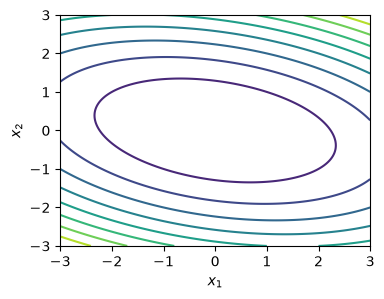

In [31]:
import matplotlib.pyplot as plt

x1 = np.linspace(-3, 3, 200)
x2 = np.linspace(-3, 3, 150)
xx1, xx2 = np.meshgrid(x1, x2)  # (150, 200) cada una

F = xx1**2 + 3 * xx2**2 + xx1 * xx2  # f(x1, x2) en cada punto -> (150, 200)

plt.figure(figsize=(4, 3))
plt.contour(xx1, xx2, F, levels=10)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.show()

---
#### 12. Errores frecuentes: lista de control

---
#### 13. Autoevaluación